# TASK 2
## Activity 1: Dataset Summary.

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import ast
import re
from pathlib import Path
from collections import Counter

# Load the original dataset
data_path = Path("../data/raw/ted_talks_en.csv")
df = pd.read_csv(data_path)

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset loaded successfully!
Number of rows: 4005
Number of columns: 19


In [20]:
# Display the first five records
display(df.head())

# Display column names and data types
display(pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str).values
}))

# Display dataset information
df.info()

,talk_id,title,speaker_1,all_speakers,occupations,about_speakers,views,recorded_date,published_date,event,native_lang,available_lang,comments,duration,topics,related_talks,url,description,transcript
0,1,Averting the climate crisis,Al Gore,{0: 'Al Gore'},{0: ['climate advocate']},{0: 'Nobel Laureate Al Gore focused the world’...,3523392,2006-02-25,2006-06-27,TED2006,en,"['ar', 'bg', 'cs', 'de', 'el', 'en', 'es', 'fa...",272.0,977,"['alternative energy', 'cars', 'climate change...","{243: 'New thinking on the climate crisis', 54...",https://www.ted.com/talks/al_gore_averting_the...,With the same humor and humanity he exuded in ...,"Thank you so much, Chris. And it's truly a gre..."
1,92,The best stats you've ever seen,Hans Rosling,{0: 'Hans Rosling'},{0: ['global health expert; data visionary']},"{0: 'In Hans Rosling’s hands, data sings. Glob...",14501685,2006-02-22,2006-06-27,TED2006,en,"['ar', 'az', 'bg', 'bn', 'bs', 'cs', 'da', 'de...",628.0,1190,"['Africa', 'Asia', 'Google', 'demo', 'economic...","{2056: ""Own your body's data"", 2296: 'A visual...",https://www.ted.com/talks/hans_rosling_the_bes...,You've never seen data presented like this. Wi...,"About 10 years ago, I took on the task to teac..."
2,7,Simplicity sells,David Pogue,{0: 'David Pogue'},{0: ['technology columnist']},{0: 'David Pogue is the personal technology co...,1920832,2006-02-24,2006-06-27,TED2006,en,"['ar', 'bg', 'de', 'el', 'en', 'es', 'fa', 'fr...",124.0,1286,"['computers', 'entertainment', 'interface desi...","{1725: '10 top time-saving tech tips', 2274: '...",https://www.ted.com/talks/david_pogue_simplici...,New York Times columnist David Pogue takes aim...,"(Music: ""The Sound of Silence,"" Simon & Garfun..."
3,53,Greening the ghetto,Majora Carter,{0: 'Majora Carter'},{0: ['activist for environmental justice']},{0: 'Majora Carter redefined the field of envi...,2664069,2006-02-26,2006-06-27,TED2006,en,"['ar', 'bg', 'bn', 'ca', 'cs', 'de', 'en', 'es...",219.0,1116,"['MacArthur grant', 'activism', 'business', 'c...",{1041: '3 stories of local eco-entrepreneurshi...,https://www.ted.com/talks/majora_carter_greeni...,"In an emotionally charged talk, MacArthur-winn...",If you're here today — and I'm very happy that...
4,66,Do schools kill creativity?,Sir Ken Robinson,{0: 'Sir Ken Robinson'},"{0: ['author', 'educator']}","{0: ""Creativity expert Sir Ken Robinson challe...",65051954,2006-02-25,2006-06-27,TED2006,en,"['af', 'ar', 'az', 'be', 'bg', 'bn', 'ca', 'cs...",4931.0,1164,"['children', 'creativity', 'culture', 'dance',...","{865: 'Bring on the learning revolution!', 173...",https://www.ted.com/talks/sir_ken_robinson_do_...,Sir Ken Robinson makes an entertaining and pro...,Good morning. How are you? (Audience) Good. It...


,Column,Data Type
0,talk_id,int64
1,title,str
2,speaker_1,str
3,all_speakers,str
4,occupations,str
5,about_speakers,str
6,views,int64
7,recorded_date,str
8,published_date,str
9,event,str


<class 'pandas.DataFrame'>
RangeIndex: 4005 entries, 0 to 4004
Data columns (total 19 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   talk_id         4005 non-null   int64  
 1   title           4005 non-null   str    
 2   speaker_1       4005 non-null   str    
 3   all_speakers    4001 non-null   str    
 4   occupations     3483 non-null   str    
 5   about_speakers  3502 non-null   str    
 6   views           4005 non-null   int64  
 7   recorded_date   4004 non-null   str    
 8   published_date  4005 non-null   str    
 9   event           4005 non-null   str    
 10  native_lang     4005 non-null   str    
 11  available_lang  4005 non-null   str    
 12  comments        3350 non-null   float64
 13  duration        4005 non-null   int64  
 14  topics          4005 non-null   str    
 15  related_talks   4005 non-null   str    
 16  url             4005 non-null   str    
 17  description     4005 non-null   str    
 18 

In [21]:
 # Generate descriptive statistics
 display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
talk_id,4005.0,NaN,NaN,NaN,12432.538327,17447.576262,1.0,1252.0,2333.0,23777.0,62794.0
title,4005,4005,Averting the climate crisis,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
speaker_1,4005,3274,Alex Gendler,34,NaN,NaN,NaN,NaN,NaN,NaN,NaN
all_speakers,4001,3306,{0: 'Alex Gendler'},34,NaN,NaN,NaN,NaN,NaN,NaN,NaN
occupations,3483,2049,{0: ['writer']},53,NaN,NaN,NaN,NaN,NaN,NaN,NaN
about_speakers,3502,2977,{0: 'Alex Rosenthal takes everyday experiences...,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
views,4005.0,NaN,NaN,NaN,2148005.573783,3451225.523659,0.0,882069.0,1375508.0,2133110.0,65051954.0
recorded_date,4004,1334,2017-04-24,97,NaN,NaN,NaN,NaN,NaN,NaN,NaN
published_date,4005,2962,2017-09-07,27,NaN,NaN,NaN,NaN,NaN,NaN,NaN
event,4005,459,TED-Ed,556,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [22]:
# check the unique talk identifiers
if "talk_id" in df.columns:
    print("Unique talk IDs:", df["talk_id"].nunique())
else:
    print("talk_id column is not available.")

Unique talk IDs: 4005


## Activity 2: Missing Values and Duplicates

In [23]:
# A. Calculate missing-value counts and percentages
missing_report = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().sum() / len(df) * 100
    ).round(2)
})

missing_report = missing_report.sort_values(
    "Missing_Count", ascending=False
)

display(missing_report)

,Missing_Count,Missing_Percentage
comments,655,16.35
occupations,522,13.03
about_speakers,503,12.56
all_speakers,4,0.10
recorded_date,1,0.02
talk_id,0,0.00
title,0,0.00
speaker_1,0,0.00
views,0,0.00
event,0,0.00


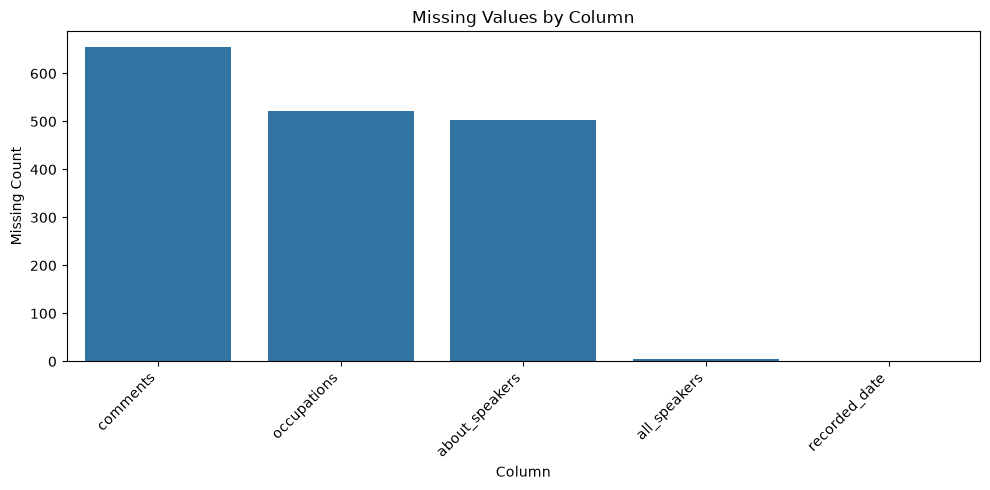

In [24]:
# B. Visualize missing values
missing_nonzero = missing_report[
    missing_report["Missing_Count"] > 0
]

if not missing_nonzero.empty:
    plt.figure(figsize=(10, 5))
    sns.barplot(
        data=missing_nonzero.reset_index(),
        x="index",
        y="Missing_Count"
    )
    plt.title("Missing Values by Column")
    plt.xlabel("Column")
    plt.ylabel("Missing Count")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found.")

In [25]:
# C. Check duplicate rows and talk IDs
print("Duplicate rows:", df.duplicated().sum())

if "talk_id" in df.columns:
    print("Repeated talk IDs:", df["talk_id"].duplicated().sum())
else:
    print("No talk_id column available.")

Duplicate rows: 0
Repeated talk IDs: 0


In [26]:
# D. Check missing or empty important fields
important_columns = [
    "title", "description", "topics", "transcript", "url"
]

for col in important_columns:
    if col in df.columns:
        text = df[col].astype("string").str.strip()
        empty = text.isna() | text.eq("")
        print(
            f"{col}: missing={df[col].isna().sum()}, "
            f"empty={empty.sum()}"
        )
    else:
        print(f"{col}: column not available")

title: missing=0, empty=0
description: missing=0, empty=0
topics: missing=0, empty=0
transcript: missing=0, empty=0
url: missing=0, empty=0


## Activity 3: Text Analysis

In [27]:
# A. Calculate text lengths and word counts

# Identify which text columns are available
text_columns = ["description", "transcript"]

for col in text_columns:
    if col not in df.columns:
        print(f"{col} is not available in the dataset.")
        continue

    text = df[col].fillna("").astype(str).str.strip()

    print(f"\n{col}")
    print("Empty entries:", text.eq("").sum())
    print("Average word count:",
          text.apply(lambda x: len(x.split())).mean())
    print("Minimum word count:",
          text.apply(lambda x: len(x.split())).min())
    print("Maximum word count:",
          text.apply(lambda x: len(x.split())).max())


description
Empty entries: 0
Average word count: 58.19550561797753
Minimum word count: 9
Maximum word count: 143

transcript
Empty entries: 0
Average word count: 1796.845692883895
Minimum word count: 2
Maximum word count: 11121


In [28]:
# create word-count columns in a separate analysis copy

text_df = df.copy()

for col in ["description", "transcript"]:
    if col in text_df.columns:
        text_df[col + "_word_count"] = (
            text_df[col]
            .fillna("")
            .astype(str)
            .str.split()
            .str.len()
        )

display(text_df.head())

,talk_id,title,speaker_1,all_speakers,occupations,about_speakers,views,recorded_date,published_date,event,...,available_lang,comments,duration,topics,related_talks,url,description,transcript,description_word_count,transcript_word_count
0,1,Averting the climate crisis,Al Gore,{0: 'Al Gore'},{0: ['climate advocate']},{0: 'Nobel Laureate Al Gore focused the world’...,3523392,2006-02-25,2006-06-27,TED2006,...,"['ar', 'bg', 'cs', 'de', 'el', 'en', 'es', 'fa...",272.0,977,"['alternative energy', 'cars', 'climate change...","{243: 'New thinking on the climate crisis', 54...",https://www.ted.com/talks/al_gore_averting_the...,With the same humor and humanity he exuded in ...,"Thank you so much, Chris. And it's truly a gre...",39,2153
1,92,The best stats you've ever seen,Hans Rosling,{0: 'Hans Rosling'},{0: ['global health expert; data visionary']},"{0: 'In Hans Rosling’s hands, data sings. Glob...",14501685,2006-02-22,2006-06-27,TED2006,...,"['ar', 'az', 'bg', 'bn', 'bs', 'cs', 'da', 'de...",628.0,1190,"['Africa', 'Asia', 'Google', 'demo', 'economic...","{2056: ""Own your body's data"", 2296: 'A visual...",https://www.ted.com/talks/hans_rosling_the_bes...,You've never seen data presented like this. Wi...,"About 10 years ago, I took on the task to teac...",26,3174
2,7,Simplicity sells,David Pogue,{0: 'David Pogue'},{0: ['technology columnist']},{0: 'David Pogue is the personal technology co...,1920832,2006-02-24,2006-06-27,TED2006,...,"['ar', 'bg', 'de', 'el', 'en', 'es', 'fa', 'fr...",124.0,1286,"['computers', 'entertainment', 'interface desi...","{1725: '10 top time-saving tech tips', 2274: '...",https://www.ted.com/talks/david_pogue_simplici...,New York Times columnist David Pogue takes aim...,"(Music: ""The Sound of Silence,"" Simon & Garfun...",31,3371
3,53,Greening the ghetto,Majora Carter,{0: 'Majora Carter'},{0: ['activist for environmental justice']},{0: 'Majora Carter redefined the field of envi...,2664069,2006-02-26,2006-06-27,TED2006,...,"['ar', 'bg', 'bn', 'ca', 'cs', 'de', 'en', 'es...",219.0,1116,"['MacArthur grant', 'activism', 'business', 'c...",{1041: '3 stories of local eco-entrepreneurshi...,https://www.ted.com/talks/majora_carter_greeni...,"In an emotionally charged talk, MacArthur-winn...",If you're here today — and I'm very happy that...,31,3071
4,66,Do schools kill creativity?,Sir Ken Robinson,{0: 'Sir Ken Robinson'},"{0: ['author', 'educator']}","{0: ""Creativity expert Sir Ken Robinson challe...",65051954,2006-02-25,2006-06-27,TED2006,...,"['af', 'ar', 'az', 'be', 'bg', 'bn', 'ca', 'cs...",4931.0,1164,"['children', 'creativity', 'culture', 'dance',...","{865: 'Bring on the learning revolution!', 173...",https://www.ted.com/talks/sir_ken_robinson_do_...,Sir Ken Robinson makes an entertaining and pro...,Good morning. How are you? (Audience) Good. It...,21,3170


In [29]:
# B. Identify empty and unusually short text

thresholds = {
    "description": 10,
    "transcript": 20
}

for col, threshold in thresholds.items():
    if col in text_df.columns:
        word_col = col + "_word_count"

        short_text = text_df[word_col] < threshold

        print(f"\n{col}")
        print("Entries below", threshold, "words:",
              short_text.sum())

        display(
            text_df.loc[short_text, [col, word_col]].head(5)
        )


description
Entries below 10 words: 1


,description,description_word_count
84,"A happy song about global warming, from Jill S...",9



transcript
Entries below 20 words: 8


,transcript,transcript_word_count
145,(Applause) (Music) (Applause),3
904,(Music) (Applause) (Music) (Applause),4
1198,(Music) (Applause) (Music) (Applause) (Music) ...,8
1393,(Mechanical noises) (Music) (Applause),4
1825,(Music) (Applause),2


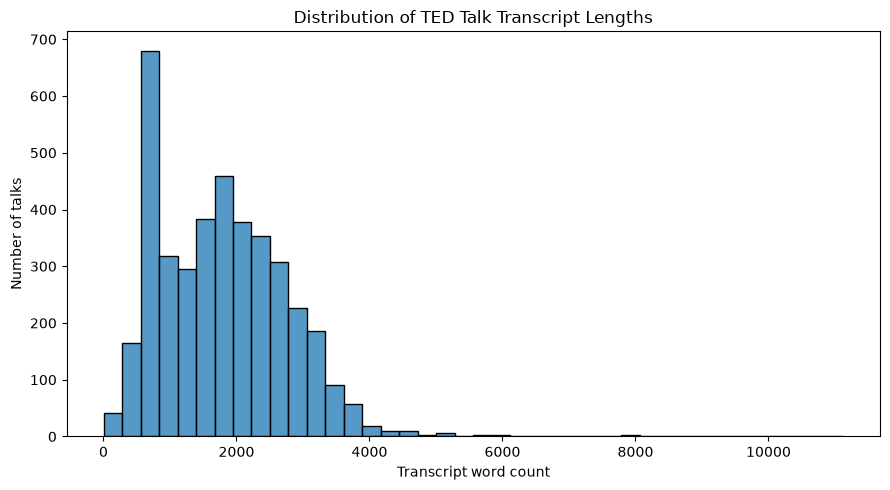

In [30]:
# C. Visualize transcript-length distribution

if "transcript_word_count" in text_df.columns:
    plt.figure(figsize=(9, 5))
    sns.histplot(
        data=text_df,
        x="transcript_word_count",
        bins=40
    )
    plt.title("Distribution of TED Talk Transcript Lengths")
    plt.xlabel("Transcript word count")
    plt.ylabel("Number of talks")
    plt.tight_layout()
    plt.show()

## Activity 4: Tag and Topic Analysis

In [31]:
# A. Inspect the topic format

if "topics" in df.columns:
    print("Example topic values:")
    display(df["topics"].head(10))
else:
    print("The topics column is not available.")

Example topic values:


0    ['alternative energy', 'cars', 'climate change...
1    ['Africa', 'Asia', 'Google', 'demo', 'economic...
2    ['computers', 'entertainment', 'interface desi...
3    ['MacArthur grant', 'activism', 'business', 'c...
4    ['children', 'creativity', 'culture', 'dance',...
5    ['architecture', 'collaboration', 'culture', '...
6    ['Christianity', 'God', 'atheism', 'comedy', '...
7    ['God', 'atheism', 'brain', 'cognitive science...
8    ['Christianity', 'God', 'culture', 'happiness'...
9    ['TED Prize', 'culture', 'entertainment', 'fil...
Name: topics, dtype: str

In [32]:
# B. Process and count topics

def extract_topics(value):
    if pd.isna(value):
        return []

    if isinstance(value, list):
        items = value
    else:
        value = str(value).strip()

        try:
            parsed = ast.literal_eval(value)
            items = parsed if isinstance(parsed, list) else [value]
        except (ValueError, SyntaxError):
            items = [value]

    return [
        str(item).strip().lower()
        for item in items
        if str(item).strip()
    ]


if "topics" in df.columns:
    topic_lists = df["topics"].apply(extract_topics)
    topic_counts = Counter(
        topic
        for topics in topic_lists
        for topic in topics
    )

    top_topics = pd.DataFrame(
        topic_counts.most_common(15),
        columns=["Topic", "Frequency"]
    )

    display(top_topics)

,Topic,Frequency
0,science,993
1,technology,979
2,culture,680
3,tedx,581
4,global issues,574
5,ted-ed,563
6,society,557
7,design,518
8,social change,512
9,animation,487


Top 15 Most Frequent TED Talk Topics:
        Topic  Frequency
      science        993
   technology        979
      culture        680
         tedx        581
global issues        574
       ted-ed        563
      society        557
       design        518
social change        512
    animation        487
     business        443
       health        442
      history        406
    education        390
     humanity        388


<Figure size 1000x600 with 0 Axes>

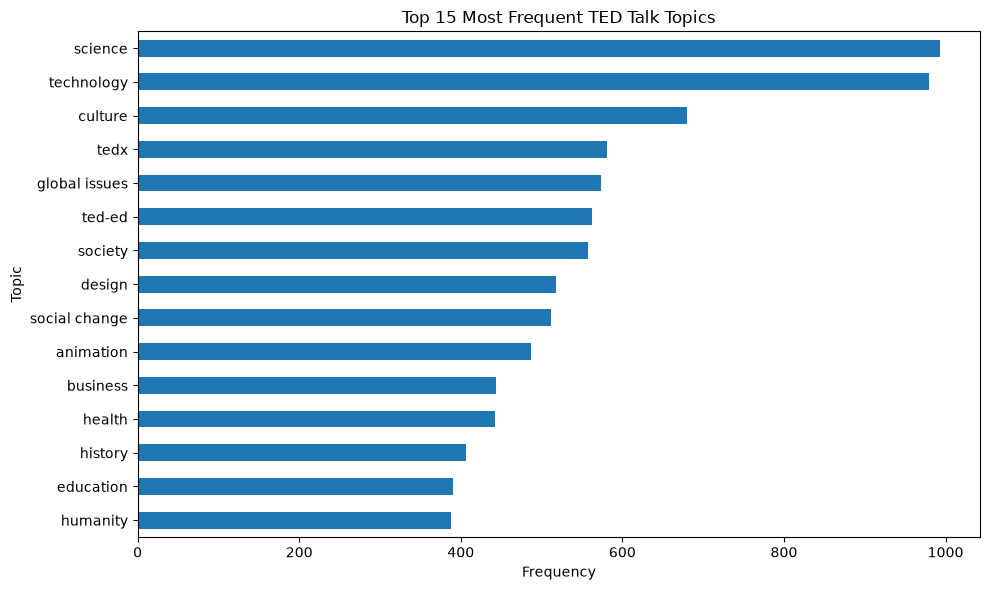

In [33]:
# C. Visualize the top 15 topics
import matplotlib.pyplot as plt

# Get the top 15 topics from the Counter object
top_topics = topic_counts.most_common(15)

# Convert to a DataFrame
top_topics_df = pd.DataFrame(
    top_topics, columns=["Topic", "Frequency"]
)

# Print the exact counts
print("Top 15 Most Frequent TED Talk Topics:")
print(top_topics_df.to_string(index=False))

# Plot the top 15 topics
plt.figure(figsize=(10, 6))
top_topics_df.sort_values("Frequency").plot(
    x="Topic", y="Frequency", kind="barh",
    legend=False, figsize=(10, 6)
)

plt.title("Top 15 Most Frequent TED Talk Topics")
plt.xlabel("Frequency")
plt.ylabel("Topic")
plt.tight_layout()
plt.show()


### D. Observation — Topic Frequency Analysis

The analysis shows that Science (993) and Technology (979) are the most frequent topics, followed by Culture (680). Other popular topics include TEDx, Global Issues, TED-Ed, and Society. These results indicate that science and technology are strongly represented in the dataset. Topic frequencies can help the recommendation system suggest TED Talks based on users' interests.

## Activity 5: Views and Duration Analysis

In [34]:
# A. Descriptive statistics

for col in ["views", "duration"]:
    if col in df.columns:
        print(f"\nStatistics for {col}:")
        display(df[col].describe())
    else:
        print(f"{col} is not available in the dataset.")


Statistics for views:


count    4.005000e+03
mean     2.148006e+06
std      3.451226e+06
min      0.000000e+00
25%      8.820690e+05
50%      1.375508e+06
75%      2.133110e+06
max      6.505195e+07
Name: views, dtype: float64


Statistics for duration:


count    4005.000000
mean      724.011236
std       361.775462
min        60.000000
25%       393.000000
50%       738.000000
75%       974.000000
max      3922.000000
Name: duration, dtype: float64

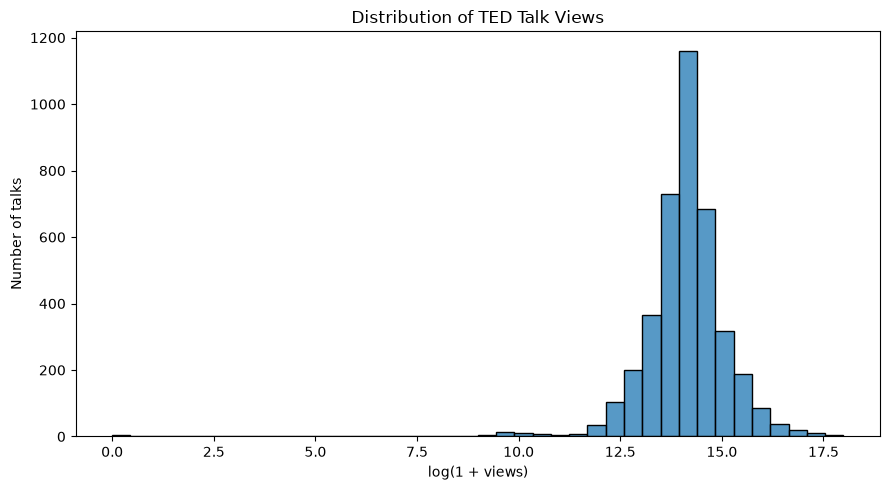

Negative view counts: 0


In [35]:
# B. Visualize views

if "views" in df.columns:
    views = pd.to_numeric(df["views"], errors="coerce")
    valid_views = views[views >= 0]

    plt.figure(figsize=(9, 5))
    sns.histplot(
        x=np.log1p(valid_views),
        bins=40
    )
    plt.title("Distribution of TED Talk Views")
    plt.xlabel("log(1 + views)")
    plt.ylabel("Number of talks")
    plt.tight_layout()
    plt.show()

    print("Negative view counts:", (views < 0).sum())

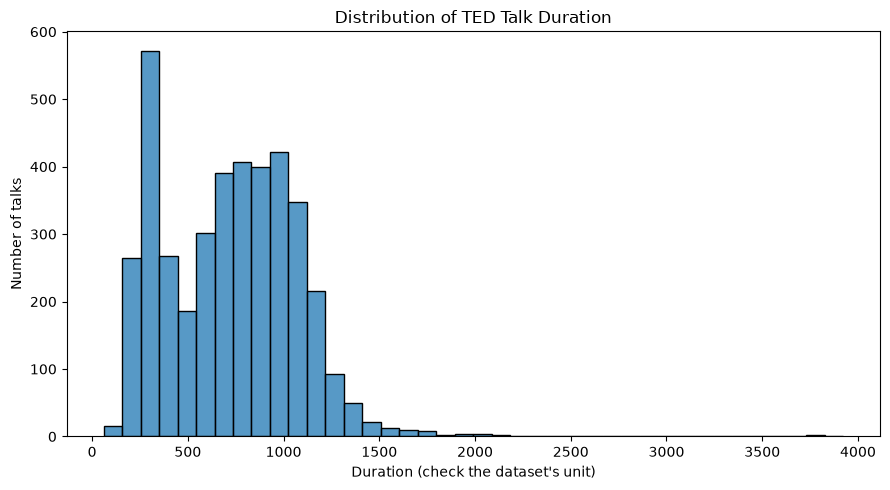

Negative duration values: 0


In [18]:
# C. Visualize duration

if "duration" in df.columns:
    duration = pd.to_numeric(df["duration"], errors="coerce")
    valid_duration = duration[duration >= 0]

    plt.figure(figsize=(9, 5))
    sns.histplot(x=valid_duration, bins=40)
    plt.title("Distribution of TED Talk Duration")
    plt.xlabel("Duration (check the dataset's unit)")
    plt.ylabel("Number of talks")
    plt.tight_layout()
    plt.show()

    print("Negative duration values:", (duration < 0).sum())

### D. Observations — Views and Duration Analysis

1. Views Analysis

The dataset contains 4,005 valid numerical view entries. The average number of views is approximately 2,148,006, while the median is 1,375,508. The minimum number of views is 0, and the maximum is 65,051,950. The standard deviation is approximately 3,451,226, indicating considerable variation in the number of views across TED Talks. The histogram of log-transformed views shows that most talks are concentrated within a central range, while some talks have substantially higher view counts. No negative view values were found.

2. Duration Analysis

The dataset contains 4,005 valid numerical duration entries. The average duration value is approximately 724.01, while the median is 738. The minimum duration is 60, and the maximum is 3,922. The standard deviation is approximately 361.78. The histogram shows that many talks have duration values between approximately 200 and 1,200, with fewer talks having much longer durations. The distribution is somewhat right-skewed, with a small number of unusually long talks. No negative duration values were found.

3. Overall Finding

The analysis shows that views vary considerably across TED Talks, suggesting that some talks are much more popular than others. Duration also varies, although many talks fall within a more concentrated range. These features may help the personalized recommendation system recommend popular talks or talks that match users' preferred viewing time. Potentially unusual values should be investigated before deciding whether they require cleaning.

## Key Findings

1. Dataset size: The dataset contains 4,005 TED Talks and 19 original columns. All 4,005 talk IDs are unique.
2. Missing values: Comments have 655 missing values, occupations have 522, and speaker descriptions have 503. These fields may be optional for recommendations or supporting information.
3. Duplicate records: No duplicate rows or repeated talk IDs were found.
4. Text quality: No missing or empty values were found in titles, descriptions, topics, transcripts, or URLs. However, eight transcripts contain fewer than 20 words and should be reviewed to determine whether they provide enough information for content-based recommendations.
5. Topic distribution: Science is the most frequent topic, followed by technology and culture. Topic information can help recommend talks with similar subjects.
6. Views and duration: Views vary considerably, while talk durations range from 60 to 3,922 in the dataset's recorded units. Unusual values should be investigated before cleaning.

## Proposed Data-Cleaning Plan

Based on the exploratory data analysis, the following data-cleaning steps are proposed to improve the quality of the TED Talks dataset before building the recommendation system.

1. Handling Missing Values: The dataset contains missing values in comments, occupations, speaker descriptions, and a few other fields. These values will be reviewed and handled according to their importance. Records will not be deleted unnecessarily because they may contain useful information.

2. Handling Duplicate Records: No duplicate rows or repeated talk IDs were found. Duplicate checks will be performed again after any future data updates to ensure that each TED Talk is uniquely identified.

3. Cleaning Text Data: Titles, descriptions, and transcripts will be checked for unnecessary spaces and inconsistent formatting. Text will be normalized where appropriate to improve text processing and similarity calculations.

4. Handling Short Transcripts: Transcripts with unusually few words will be reviewed to identify incomplete text or entries containing only applause, music, or stage directions. These records will be handled carefully based on their usefulness for recommendations.

5. Cleaning Topic Data: Topic values will be parsed consistently into individual topics. Extra spaces and inconsistent capitalization will be standardized to ensure that similar topics are treated consistently.

6. Checking Views and Duration: Unusually high or low view counts and talk durations will be investigated. Values will not be removed unless there is evidence that they are incorrect.

7. Preserving the Original Dataset: The original CSV file will remain unchanged. All preprocessing and cleaning operations will be performed on a separate working copy to preserve the original data.

Conclusion: These cleaning steps will help improve data consistency and prepare reliable text and topic features for the Personalized TED Talks Recommendation System. The proposed actions will be applied after reviewing the identified data-quality issues.